# ECG Arrhythmia Classification — Results & Visualisation

Run this notebook from the ECG project root (the folder containing `src/` and `data/`). It uses the project's existing `src.common` functions to keep loading, splitting, and feature extraction aligned with the implementation.

Models: Logistic Regression, Random Forest (substituted for the paper's SVM), and XGBoost. Classes: N, S, V, F.

**Imbalance warning:** accuracy alone is insufficient. Review macro-F1, balanced accuracy, per-class recall/F1, class-normalised confusion matrices, and precision–recall curves. Record-wise splitting is not automatically patient-wise splitting.

## 1. Imports and project setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay, matthews_corrcoef,
    cohen_kappa_score, roc_curve, auc, precision_recall_curve,
    average_precision_score
)

SEED = 2020
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    raise FileNotFoundError("Run Jupyter from the project root containing src/ and data/.")
from src.common import load_dataset, split_records, CLASSES
from src.features import extract_features

print("Project root:", ROOT)
print("Classes:", list(CLASSES))

Project root: e:\minor\NEUROCARDIO_AI\backend\models\ecg_paper_reproduction
Classes: ['N', 'S', 'V', 'F']


## 2. Load processed beats and inspect class imbalance

Signal matrix: (101410, 250) | labels: (101410,) | groups: (101410,)
Unique groups/records: 48


,class,count,percent
0,N,90592,89.332413
1,S,2781,2.742333
2,V,7235,7.134405
3,F,802,0.790849


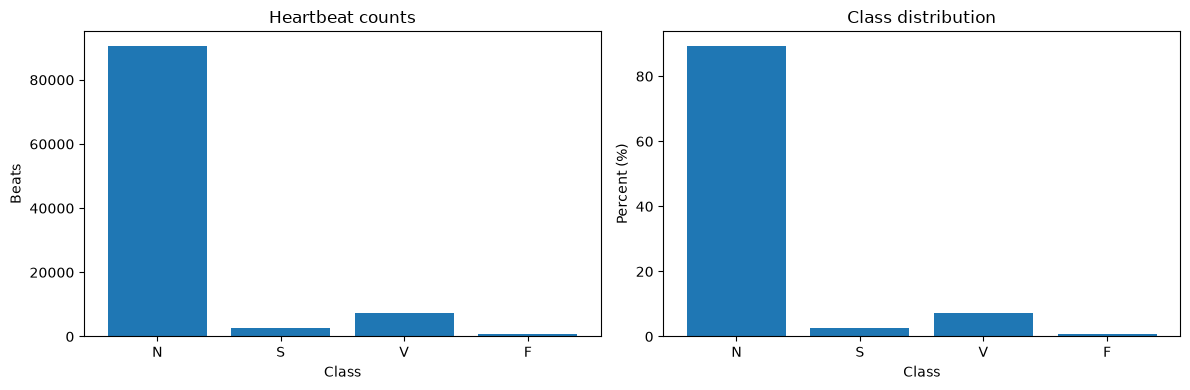

In [2]:
X, y, groups = load_dataset(str(ROOT / "data" / "processed"))
X, y, groups = np.asarray(X), np.asarray(y).astype(str), np.asarray(groups)
assert len(X) == len(y) == len(groups)
print("Signal matrix:", X.shape, "| labels:", y.shape, "| groups:", groups.shape)
print("Unique groups/records:", len(np.unique(groups)))

labels = [c for c in CLASSES if c in set(y)]
counts = pd.Series(y).value_counts().reindex(labels, fill_value=0)
class_df = pd.DataFrame({"class": labels, "count": counts.values,
                         "percent": counts.values / len(y) * 100})
display(class_df)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(class_df["class"], class_df["count"])
ax[0].set(title="Heartbeat counts", xlabel="Class", ylabel="Beats")
ax[1].bar(class_df["class"], class_df["percent"])
ax[1].set(title="Class distribution", xlabel="Class", ylabel="Percent (%)")
plt.tight_layout(); 

# Create folder for saved graphs
RESULTS_DIR = Path("results/notebook_analysis")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save graph at high resolution
plt.savefig(
    RESULTS_DIR / "heartbeat_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Plot example ECG beat segments

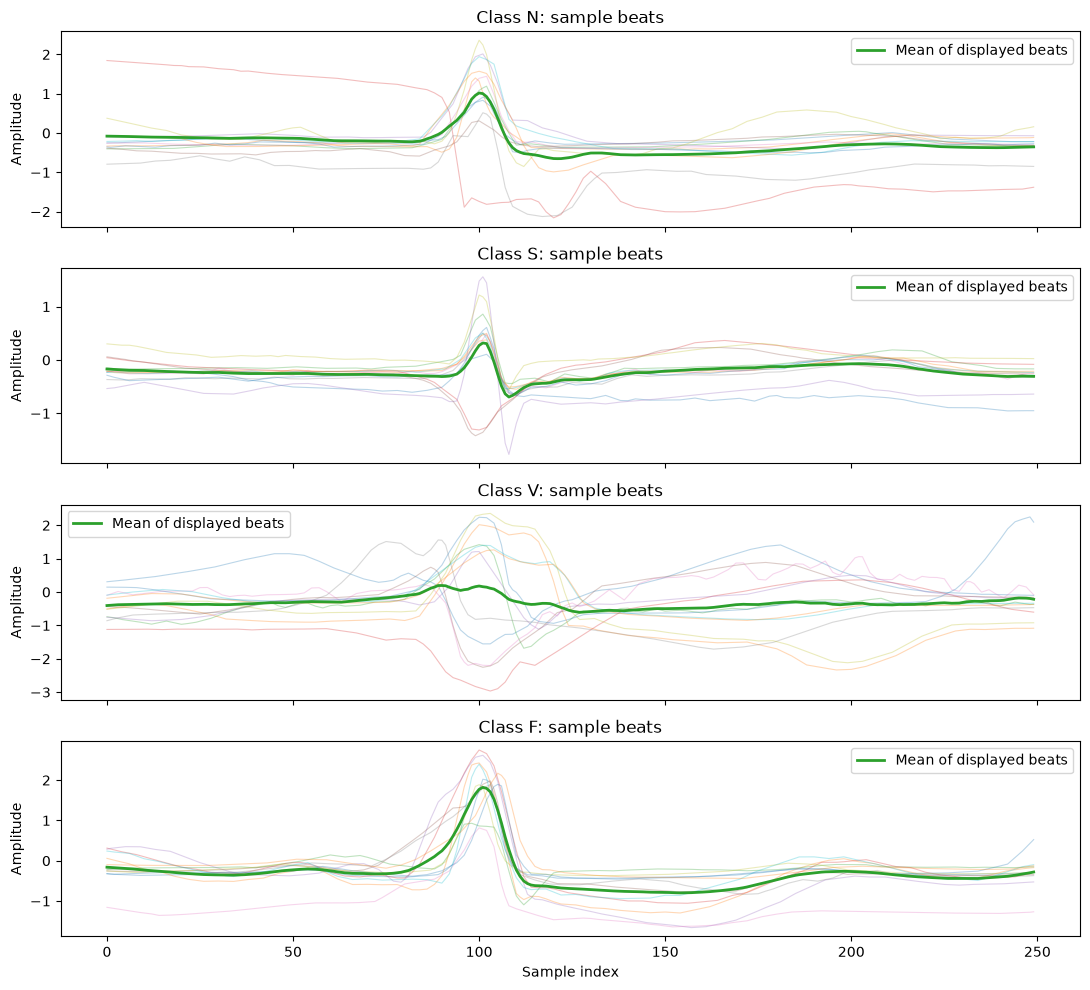

In [3]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(labels), 1, figsize=(11, 2.5 * len(labels)), sharex=True)
if len(labels) == 1: axes = [axes]
for ax, cls in zip(axes, labels):
    ids = np.flatnonzero(y == cls)
    chosen = rng.choice(ids, size=min(12, len(ids)), replace=False)
    for i in chosen: ax.plot(X[i], alpha=.3, linewidth=.8)
    ax.plot(np.mean(X[chosen], axis=0), linewidth=2, label="Mean of displayed beats")
    ax.set_title(f"Class {cls}: sample beats")
    ax.set_ylabel("Amplitude"); ax.legend()
axes[-1].set_xlabel("Sample index")
plt.tight_layout();

# Save the ECG beat-segment plots
RESULTS_DIR = Path("results/notebook_analysis")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    RESULTS_DIR / "ecg_beat_segments_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Record-wise split and feature extraction

In [4]:
train_records, val_records, test_records = split_records(groups, SEED)
tr = np.isin(groups, train_records)
va = np.isin(groups, val_records)
te = np.isin(groups, test_records)
assert set(train_records).isdisjoint(val_records)
assert set(train_records).isdisjoint(test_records)
assert set(val_records).isdisjoint(test_records)
print("Beat counts:", {"train": int(tr.sum()), "validation": int(va.sum()), "test": int(te.sum())})
print("Record counts:", {"train": len(np.unique(groups[tr])),
                         "validation": len(np.unique(groups[va])),
                         "test": len(np.unique(groups[te]))})
print("Verify in src.common whether groups are record IDs or patient IDs before claiming patient-wise evaluation.")

F = np.asarray(extract_features(X))
assert len(F) == len(y)
X_train, X_test = F[tr], F[te]
y_train, y_test = y[tr], y[te]
print("Feature matrix:", F.shape)
print("Test support:\n", pd.Series(y_test).value_counts().reindex(labels, fill_value=0))

Beat counts: {'train': 68949, 'validation': 16433, 'test': 16028}
Record counts: {'train': 33, 'validation': 7, 'test': 8}
Verify in src.common whether groups are record IDs or patient IDs before claiming patient-wise evaluation.
Feature matrix: (101410, 34)
Test support:
 N    13782
S      617
V     1607
F       22
Name: count, dtype: int64


## 5. Train traditional models

In [5]:
models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=SEED)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=SEED, n_jobs=-1
    )
}
try:
    from xgboost import XGBClassifier
    class_to_id = {c:i for i,c in enumerate(labels)}
    y_train_id = np.array([class_to_id[v] for v in y_train])
    models["XGBoost"] = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=.05,
        subsample=.9, colsample_bytree=.9, objective="multi:softprob",
        num_class=len(labels), eval_metric="mlogloss",
        random_state=SEED, n_jobs=-1
    )
except ImportError:
    print("xgboost not installed; skipping XGBoost.")

fitted, preds, probs, rows = {}, {}, {}, []
for name, model in models.items():
    if name == "XGBoost":
        model.fit(X_train, y_train_id)
        pred = np.array([labels[int(i)] for i in model.predict(X_test)])
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
    proba = model.predict_proba(X_test) if hasattr(model, "predict_proba") else None
    fitted[name], preds[name], probs[name] = model, pred, proba
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, labels=labels, zero_division=0)
    weighted_f1 = precision_recall_fscore_support(
        y_test, pred, labels=labels, average="weighted", zero_division=0
    )[2]
    rows.append({
        "Model": name, "Accuracy": accuracy_score(y_test, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "Macro precision": p.mean(), "Macro recall": r.mean(), "Macro F1": f.mean(),
        "Weighted F1": weighted_f1, "MCC": matthews_corrcoef(y_test, pred),
        "Cohen kappa": cohen_kappa_score(y_test, pred)
    })
metrics = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(metrics.style.format({c:"{:.4f}" for c in metrics.columns if c != "Model"}))

,Model,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,MCC,Cohen kappa
0,Logistic Regression,0.8948,0.4079,0.4798,0.4079,0.4315,0.8855,0.5247,0.5130
1,Random Forest,0.8895,0.3991,0.4537,0.3991,0.4206,0.8809,0.5040,0.4923
2,XGBoost,0.8709,0.4207,0.4504,0.4207,0.4185,0.8703,0.4571,0.4526


## 6. Compare aggregate metrics

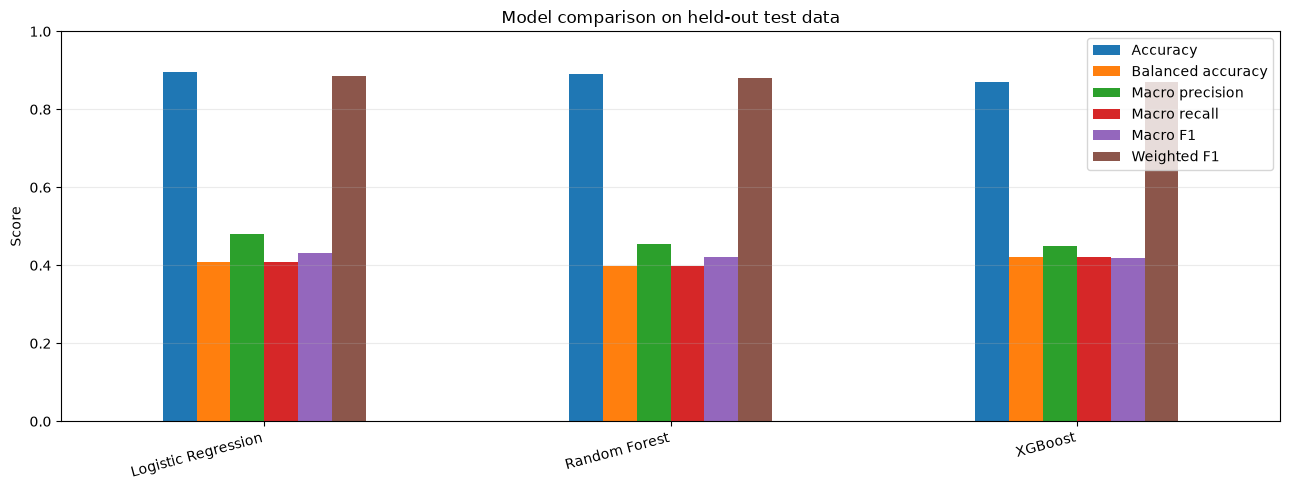

In [6]:
metric_cols = ["Accuracy", "Balanced accuracy", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"]
ax = metrics.set_index("Model")[metric_cols].plot(kind="bar", figsize=(13,5), ylim=(0,1))
ax.set_title("Model comparison on held-out test data")
ax.set_ylabel("Score"); ax.set_xlabel(""); ax.grid(axis="y", alpha=.25)
plt.xticks(rotation=15, ha="right"); plt.tight_layout();

# Create output directory
RESULTS_DIR = Path("results/notebook_analysis")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the model comparison graph
plt.savefig(
    RESULTS_DIR / "model_comparison_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Confusion matrices: counts and row-normalised heat maps

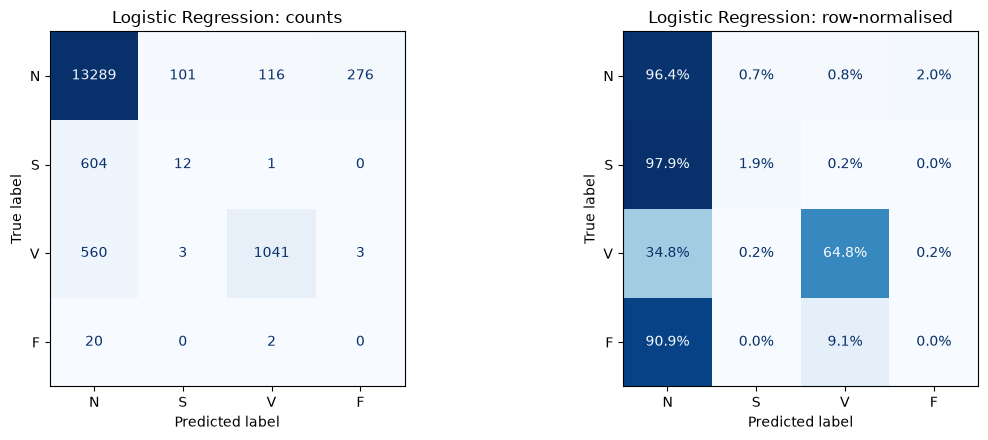

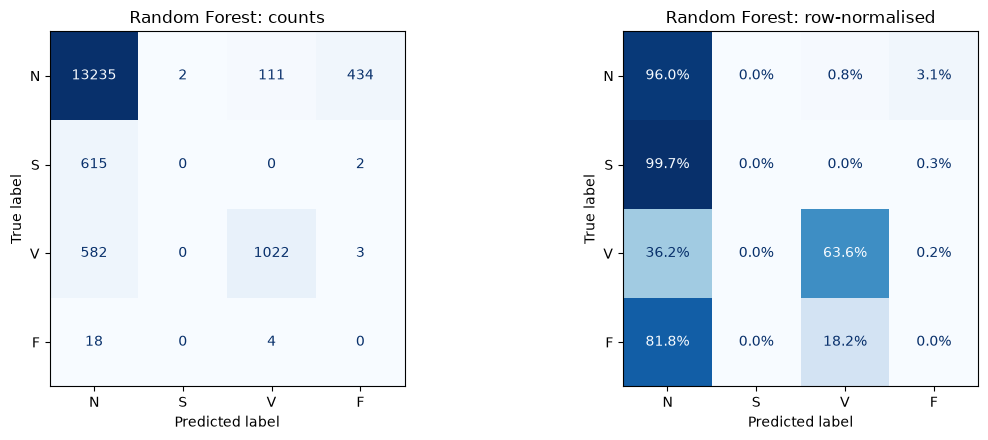

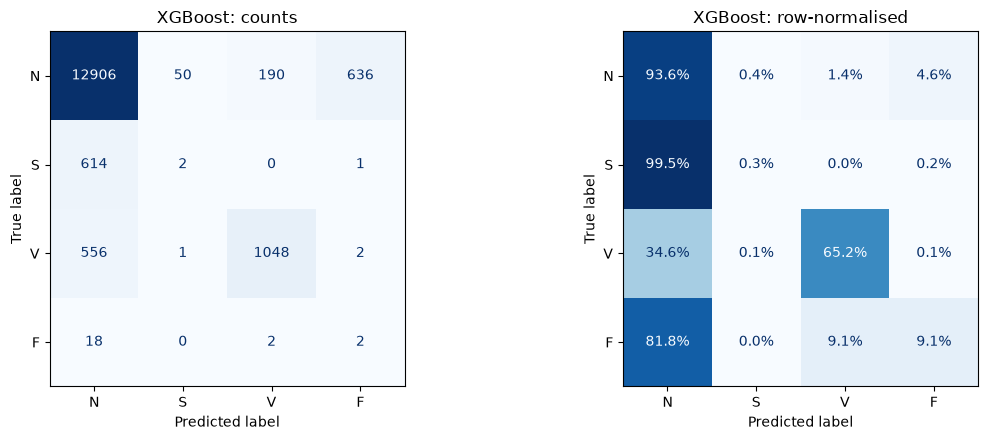

In [7]:
for name, pred in preds.items():
    cm = confusion_matrix(y_test, pred, labels=labels)
    cmn = confusion_matrix(y_test, pred, labels=labels, normalize="true")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax[0], cmap="Blues", values_format="d", colorbar=False)
    ax[0].set_title(f"{name}: counts")
    ConfusionMatrixDisplay(cmn, display_labels=labels).plot(ax=ax[1], cmap="Blues", values_format=".1%", colorbar=False)
    ax[1].set_title(f"{name}: row-normalised")
    plt.tight_layout();

    # Create folder for graph exports
    RESULTS_DIR = Path("results/notebook_analysis")
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    
    # Save both confusion matrix plots for this model
    safe_name = name.lower().replace(" ", "_")
    
    fig.savefig(
        RESULTS_DIR / f"{safe_name}_confusion_matrices.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## 8. Per-class precision, recall, F1 and support

,Model,Class,Precision,Recall,F1,Support
0,Logistic Regression,N,0.918192,0.964229,0.940648,13782
1,Logistic Regression,S,0.103448,0.019449,0.032742,617
2,Logistic Regression,V,0.897414,0.647791,0.752439,1607
3,Logistic Regression,F,0.000000,0.000000,0.000000,22
4,Random Forest,N,0.915917,0.960311,0.937589,13782
5,Random Forest,S,0.000000,0.000000,0.000000,617
6,Random Forest,V,0.898857,0.635968,0.744898,1607
7,Random Forest,F,0.000000,0.000000,0.000000,22
8,XGBoost,N,0.915709,0.936439,0.925958,13782
9,XGBoost,S,0.037736,0.003241,0.005970,617


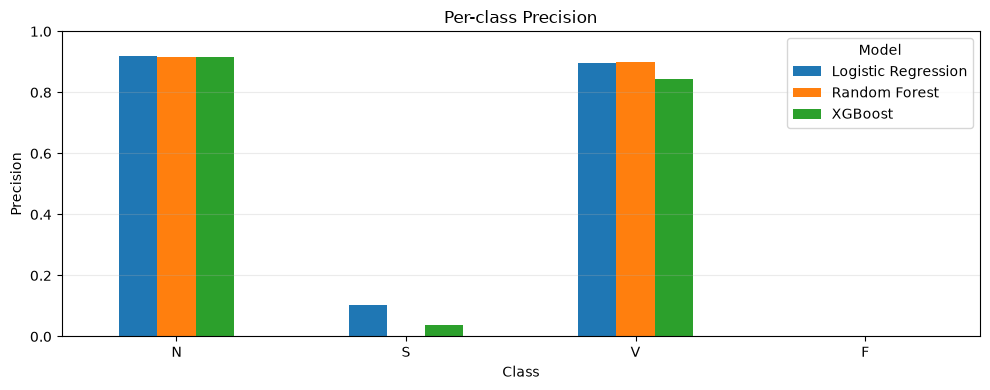

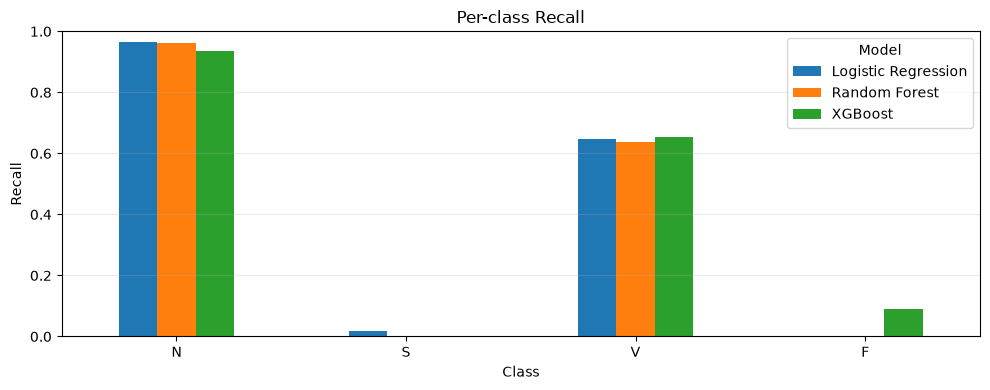

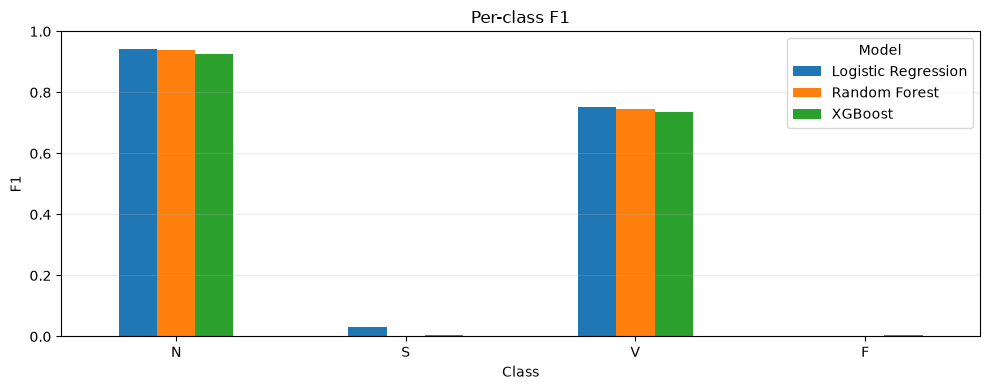

In [8]:
parts = []
for name, pred in preds.items():
    p, r, f, sup = precision_recall_fscore_support(y_test, pred, labels=labels, zero_division=0)
    parts.append(pd.DataFrame({"Model":name, "Class":labels, "Precision":p, "Recall":r, "F1":f, "Support":sup}))
per_class = pd.concat(parts, ignore_index=True)
display(per_class)
for metric in ["Precision", "Recall", "F1"]:
    pivot = per_class.pivot(index="Class", columns="Model", values=metric).reindex(labels)
    ax = pivot.plot(kind="bar", figsize=(10,4), ylim=(0,1))
    ax.set_title(f"Per-class {metric}"); ax.set_ylabel(metric); ax.grid(axis="y", alpha=.25)
    plt.xticks(rotation=0); plt.tight_layout();

    # Create the output folder
    RESULTS_DIR = Path("results/notebook_analysis")
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    
    # Save each metric plot separately
    fig = ax.get_figure()
    fig.savefig(
        RESULTS_DIR / f"per_class_{metric.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## 9. Violin plots for engineered feature distributions

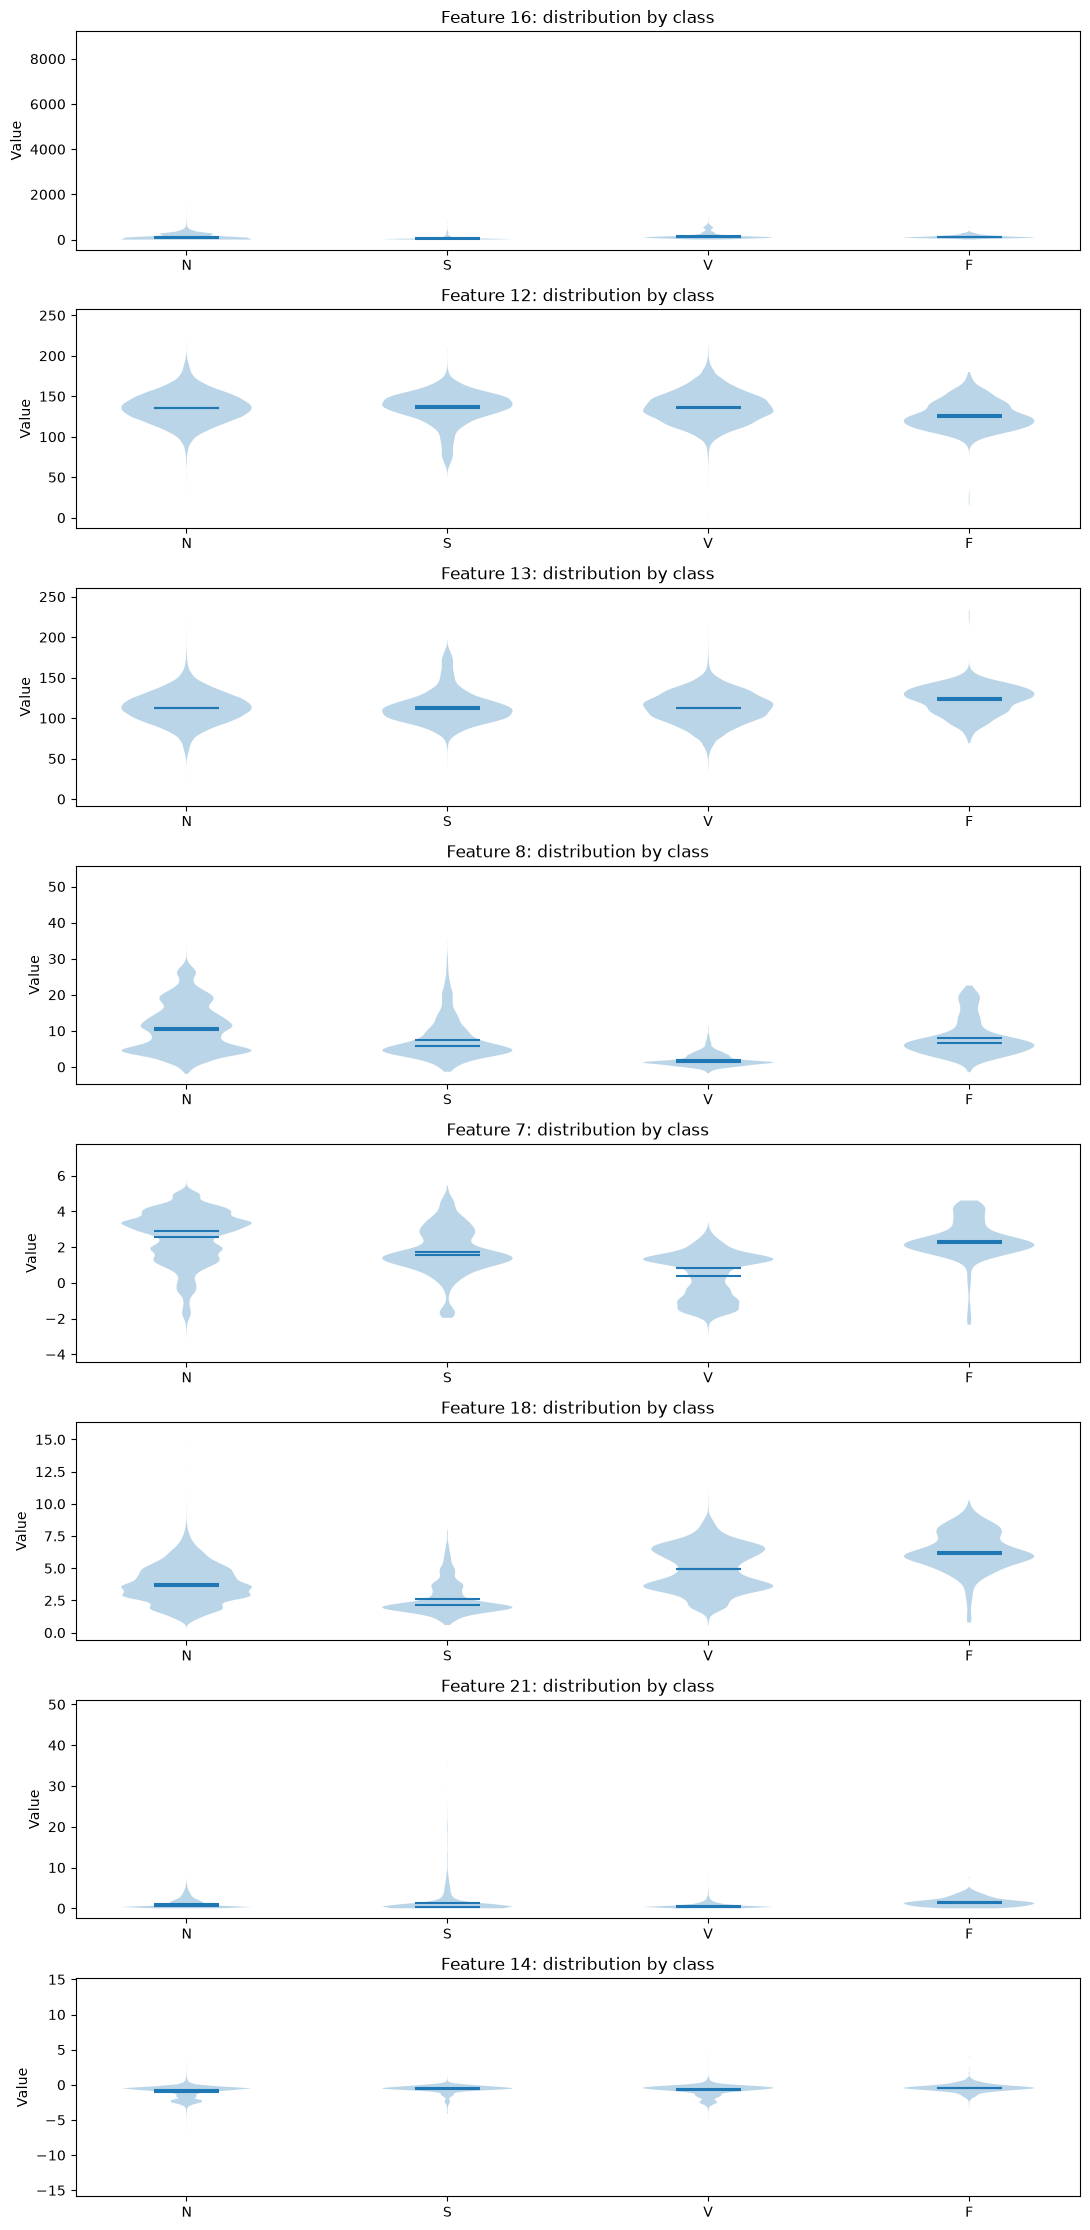

In [9]:
# Show up to eight high-variance features. Names are generic unless extract_features provides a feature-name list.
variances = np.nanvar(F, axis=0)
chosen_features = np.argsort(variances)[-min(8, F.shape[1]):][::-1]
fig, axes = plt.subplots(len(chosen_features), 1, figsize=(11, 2.8*len(chosen_features)))
if len(chosen_features) == 1: axes = [axes]
for ax, j in zip(axes, chosen_features):
    vals = [F[y == cls, j][np.isfinite(F[y == cls, j])] for cls in labels]
    ax.violinplot(vals, showmeans=True, showmedians=True, showextrema=False)
    ax.set_xticks(np.arange(1, len(labels)+1)); ax.set_xticklabels(labels)
    ax.set_title(f"Feature {j}: distribution by class"); ax.set_ylabel("Value")
plt.tight_layout();

# Create output folder
RESULTS_DIR = Path("results/notebook_analysis")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save all violin plots in one high-resolution image
plt.savefig(
    RESULTS_DIR / "ecg_feature_violin_plots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Tree-model feature importance

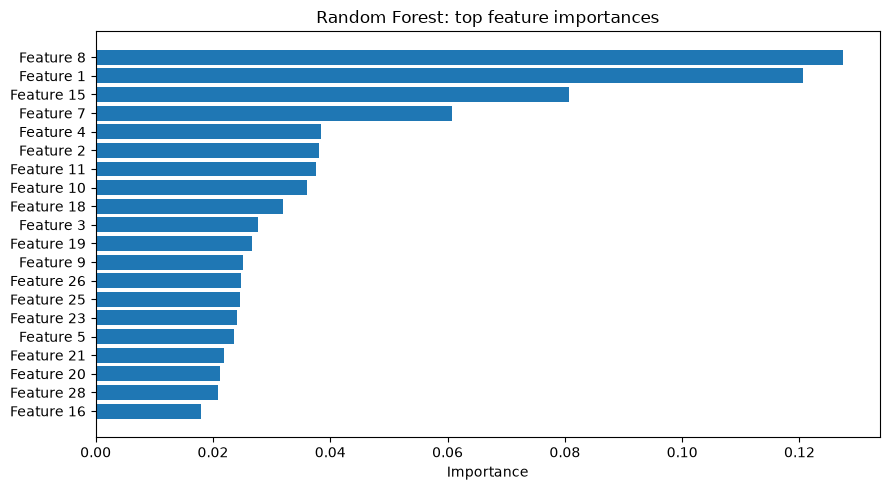

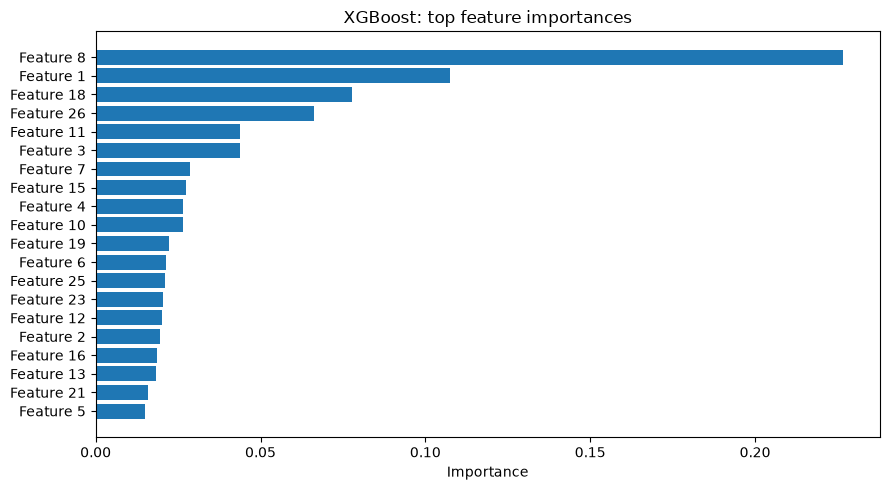

In [10]:
for name, model in fitted.items():
    estimator = model
    if hasattr(model, "named_steps"):
        estimator = list(model.named_steps.values())[-1]
    if hasattr(estimator, "feature_importances_"):
        imp = estimator.feature_importances_
        order = np.argsort(imp)[-min(20, len(imp)):]
        plt.figure(figsize=(9,5))
        plt.barh([f"Feature {i}" for i in order], imp[order])
        plt.title(f"{name}: top feature importances"); plt.xlabel("Importance")
        plt.tight_layout();

        # Create output folder
        RESULTS_DIR = Path("results/notebook_analysis")
        RESULTS_DIR.mkdir(parents=True, exist_ok=True)
        
        # Save the feature-importance plot
        safe_name = name.lower().replace(" ", "_")

        plt.savefig(
            RESULTS_DIR / f"{safe_name}_feature_importance.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

## 11. One-vs-rest ROC and precision–recall curves

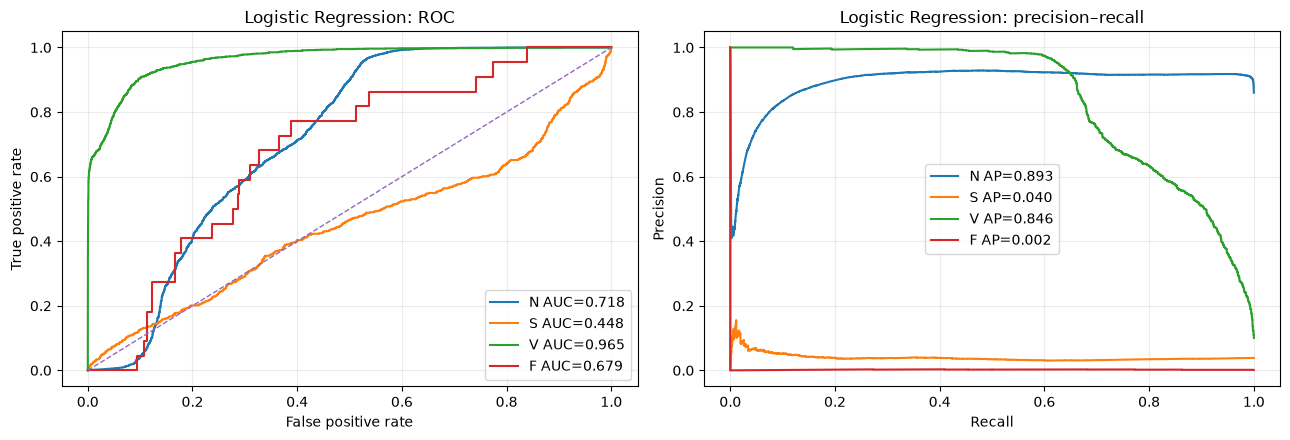

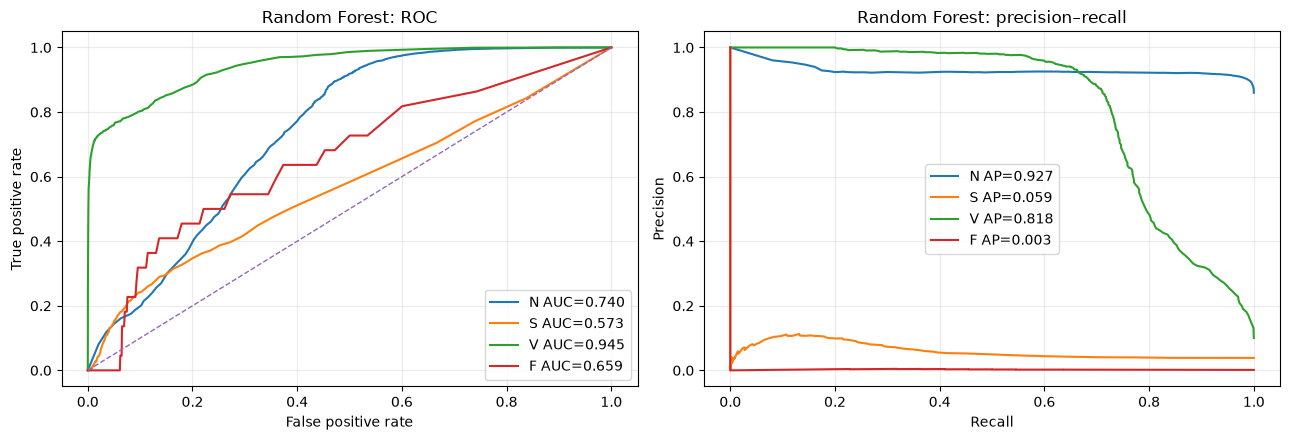

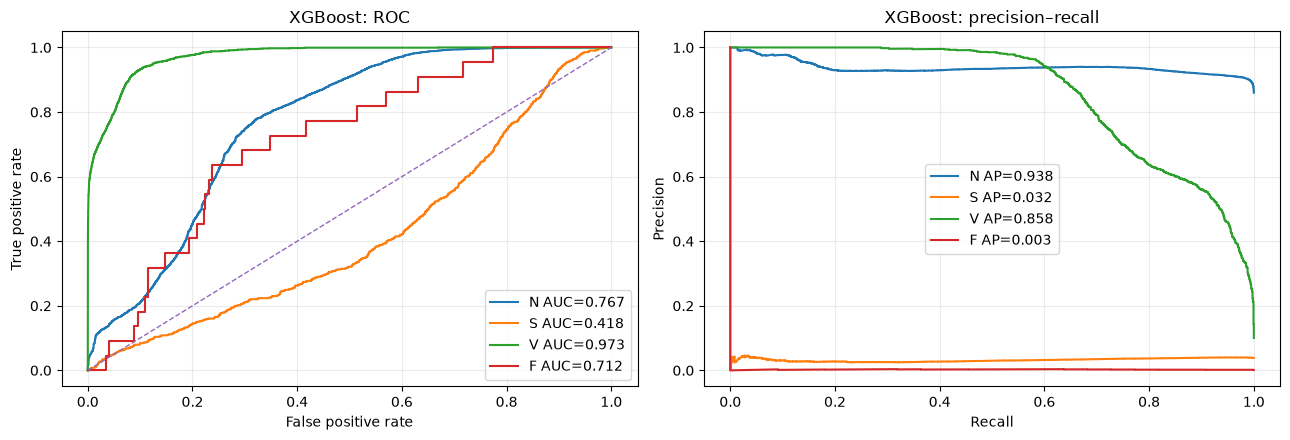

In [11]:
for name, proba in probs.items():
    if proba is None: continue
    if name == "XGBoost":
        prob_classes = labels
    else:
        prob_classes = list(fitted[name].classes_) if hasattr(fitted[name], "classes_") else labels
        if hasattr(fitted[name], "named_steps"):
            final = list(fitted[name].named_steps.values())[-1]
            if hasattr(final, "classes_"): prob_classes = list(final.classes_)
    ordered = np.zeros((len(y_test), len(labels)))
    for j, cls in enumerate(prob_classes):
        if cls in labels: ordered[:, labels.index(cls)] = proba[:, j]
    ybin = label_binarize(y_test, classes=labels)
    fig, ax = plt.subplots(1, 2, figsize=(13,4.5))
    for i, cls in enumerate(labels):
        if ybin[:,i].sum() == 0 or ybin[:,i].sum() == len(ybin): continue
        fpr, tpr, _ = roc_curve(ybin[:,i], ordered[:,i])
        pr, rc, _ = precision_recall_curve(ybin[:,i], ordered[:,i])
        ax[0].plot(fpr, tpr, label=f"{cls} AUC={auc(fpr,tpr):.3f}")
        ax[1].plot(rc, pr, label=f"{cls} AP={average_precision_score(ybin[:,i], ordered[:,i]):.3f}")
    ax[0].plot([0,1],[0,1],"--", linewidth=1)
    ax[0].set(title=f"{name}: ROC", xlabel="False positive rate", ylabel="True positive rate")
    ax[1].set(title=f"{name}: precision–recall", xlabel="Recall", ylabel="Precision")
    for a in ax: a.grid(alpha=.25); a.legend()
    plt.tight_layout();

    # Create the output folder
    RESULTS_DIR = Path("results/notebook_analysis")
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)

    # Save ROC and precision-recall curves for this model
    safe_name = name.lower().replace(" ", "_")

    fig.savefig(
        RESULTS_DIR / f"{safe_name}_roc_precision_recall.png",
        dpi=300,
        bbox_inches="tight"
   )

    plt.show()

## 12. Inspect misclassified examples and confidence

In [12]:
best = metrics.iloc[0]["Model"]
pred = preds[best]
proba = probs[best]
err = pred != y_test
error_df = pd.DataFrame({
    "source_row": np.flatnonzero(te)[err],
    "true_class": y_test[err],
    "predicted_class": pred[err],
})
if proba is not None: error_df["max_probability"] = np.max(proba[err], axis=1)
print(f"Best by macro-F1 in this run: {best}; errors: {int(err.sum()):,} / {len(err):,}")
display(error_df.head(30))
if proba is not None:
    conf = np.max(proba, axis=1)
    print("Mean confidence on correct predictions:", round(float(conf[~err].mean()), 4) if (~err).any() else None)
    print("Mean confidence on errors:", round(float(conf[err].mean()), 4) if err.any() else None)

Best by macro-F1 in this run: Logistic Regression; errors: 1,686 / 16,028


,source_row,true_class,predicted_class,max_probability
0,4232,V,N,0.818332
1,4233,V,N,0.879220
2,4234,V,N,0.908205
3,20115,S,N,0.997049
4,20472,S,N,0.990060
5,20485,S,N,0.995829
6,20583,S,N,0.961276
7,21337,S,N,0.964029
8,21404,S,N,0.999159
9,40017,S,N,0.999823


Mean confidence on correct predictions: 0.9213
Mean confidence on errors: 0.8299


## 13. Export tables and predictions

In [13]:
OUT = ROOT / "results" / "notebook_analysis"
OUT.mkdir(parents=True, exist_ok=True)
metrics.to_csv(OUT / "model_metrics.csv", index=False)
per_class.to_csv(OUT / "per_class_metrics.csv", index=False)
error_df.to_csv(OUT / "best_model_errors.csv", index=False)
pd.DataFrame({"true_label": y_test, **{f"pred_{k}":v for k,v in preds.items()}}).to_csv(OUT / "test_predictions.csv", index=False)
for name, pred in preds.items():
    safe = name.lower().replace(" ", "_")
    pd.DataFrame(confusion_matrix(y_test, pred, labels=labels), index=labels, columns=labels).to_csv(OUT/f"{safe}_confusion_counts.csv")
    pd.DataFrame(confusion_matrix(y_test, pred, labels=labels, normalize="true"), index=labels, columns=labels).to_csv(OUT/f"{safe}_confusion_normalized.csv")
print("Saved tables to:", OUT)

Saved tables to: e:\minor\NEUROCARDIO_AI\backend\models\ecg_paper_reproduction\results\notebook_analysis


## 14. How to present these results

- Start with the class-count chart to establish the imbalance.
- Show model metrics, but do not rank models by accuracy alone.
- Show row-normalised confusion matrices and per-class recall/F1 to explain which classes are missed.
- Use precision–recall curves for minority-class behaviour; ROC curves can look strong even when minority-class precision is weak.
- Use violin plots and feature importance as exploratory diagnostics, not as proof of physiological causality.
- Verify whether the split groups are records or patients before claiming patient-wise generalisation.
- The original paper uses SVM; this implementation uses Random Forest instead. State this substitution clearly.
- Do not compare directly with the paper's reported fusion accuracy unless preprocessing, features, data split, model configuration, and fusion method are aligned.

In [14]:
groups = np.load("data/processed/record_ids.npy").astype(str)

unique_records, counts = np.unique(groups, return_counts=True)

print("Total heartbeat samples:", len(groups))
print("Unique ECG records:", len(unique_records))
print("First 20 record IDs:", unique_records[:20])

for record, count in zip(unique_records[:10], counts[:10]):
    print(f"{record}: {count}")

Total heartbeat samples: 101410
Unique ECG records: 48
First 20 record IDs: ['100' '101' '102' '103' '104' '105' '106' '107' '108' '109' '111' '112'
 '113' '114' '115' '116' '117' '118' '119' '121']
100: 2271
101: 1862
102: 103
103: 2083
104: 165
105: 2567
106: 2027
107: 59
108: 1762
109: 2531


In [15]:
from src.common import split_records

groups = np.load("data/processed/record_ids.npy").astype(str)

train_records, val_records, test_records = split_records(groups)

print("Training records:", sorted(train_records))
print("Validation records:", sorted(val_records))
print("Testing records:", sorted(test_records))

print("\nRecord counts:")
print("Train:", len(train_records))
print("Validation:", len(val_records))
print("Test:", len(test_records))

print("\nOverlap checks:")
print("Train ∩ Validation:", set(train_records) & set(val_records))
print("Train ∩ Test:", set(train_records) & set(test_records))
print("Validation ∩ Test:", set(val_records) & set(test_records))

Training records: [np.str_('101'), np.str_('103'), np.str_('104'), np.str_('105'), np.str_('106'), np.str_('107'), np.str_('108'), np.str_('109'), np.str_('111'), np.str_('112'), np.str_('115'), np.str_('116'), np.str_('119'), np.str_('121'), np.str_('122'), np.str_('123'), np.str_('201'), np.str_('205'), np.str_('207'), np.str_('208'), np.str_('210'), np.str_('212'), np.str_('213'), np.str_('217'), np.str_('219'), np.str_('221'), np.str_('222'), np.str_('228'), np.str_('230'), np.str_('231'), np.str_('232'), np.str_('233'), np.str_('234')]
Validation records: [np.str_('100'), np.str_('114'), np.str_('117'), np.str_('118'), np.str_('202'), np.str_('203'), np.str_('215')]
Testing records: [np.str_('102'), np.str_('113'), np.str_('124'), np.str_('200'), np.str_('209'), np.str_('214'), np.str_('220'), np.str_('223')]

Record counts:
Train: 33
Validation: 7
Test: 8

Overlap checks:
Train ∩ Validation: set()
Train ∩ Test: set()
Validation ∩ Test: set()


,experiment,model,class,precision,recall,f1_score,support
0,baseline,logistic_regression,N,0.9117,0.6434,0.7544,13782.0
1,baseline,logistic_regression,S,0.0456,0.2220,0.0756,617.0
2,baseline,logistic_regression,V,0.9352,0.7100,0.8072,1607.0
3,baseline,logistic_regression,F,0.0014,0.1364,0.0029,22.0
4,baseline,random_forest,N,0.9170,0.9567,0.9364,13782.0
5,baseline,random_forest,S,0.0000,0.0000,0.0000,617.0
6,baseline,random_forest,V,0.8755,0.6521,0.7475,1607.0
7,baseline,random_forest,F,0.0000,0.0000,0.0000,22.0
8,baseline,xgboost,N,0.9175,0.9361,0.9267,13782.0
9,baseline,xgboost,S,0.0130,0.0016,0.0029,617.0


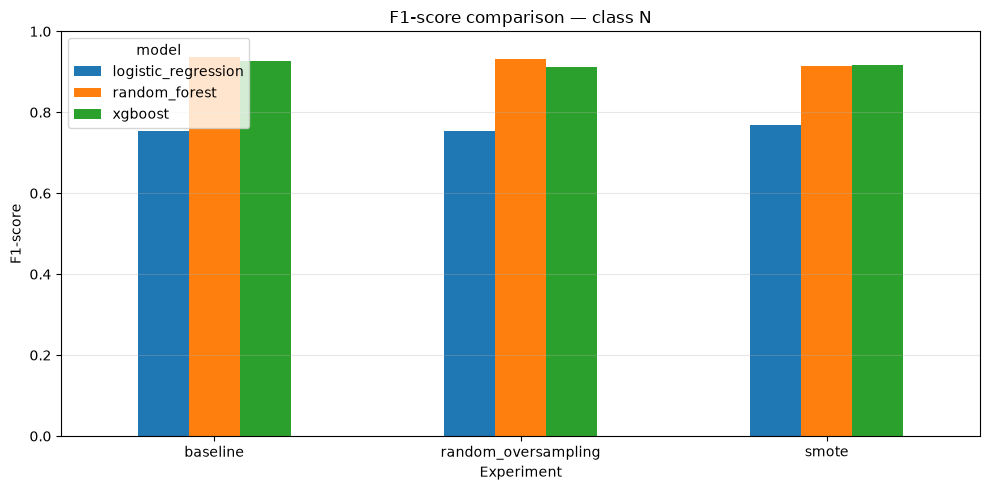

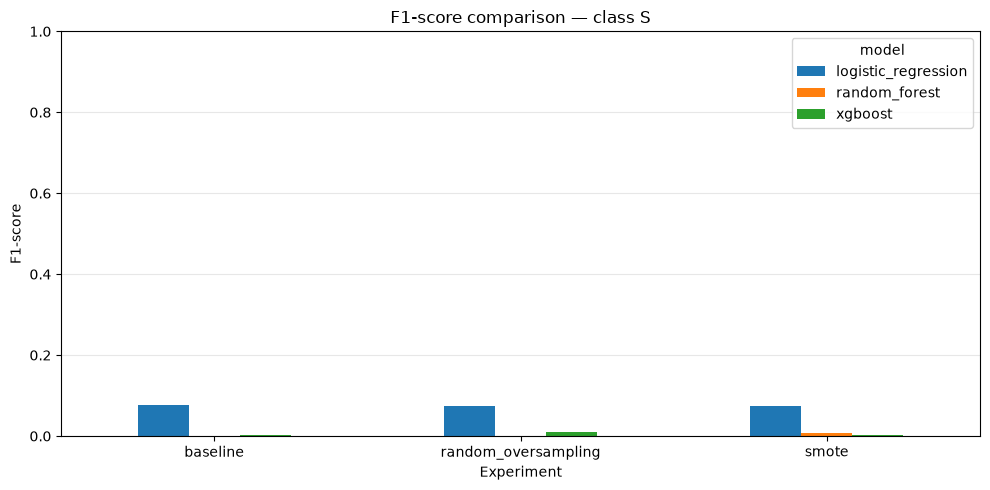

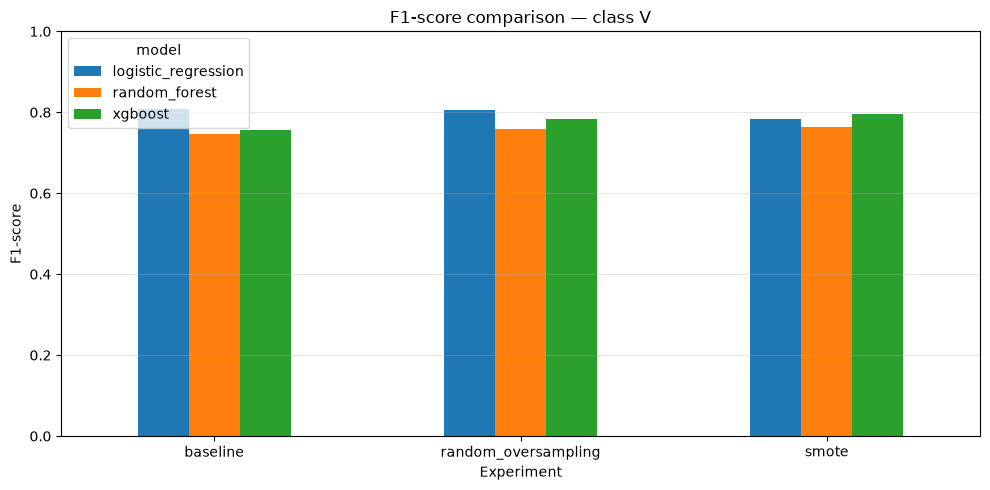

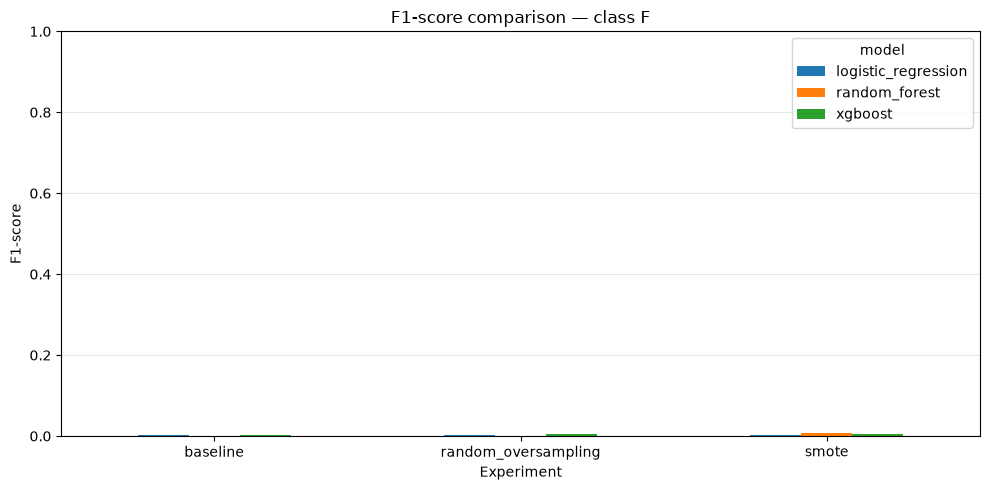

Saved comparison table and charts to: results\notebook_analysis


In [17]:
import json

RESULTS_DIR = Path("results/resampling_experiment")
OUTPUT_DIR = Path("results/notebook_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["N", "S", "V", "F"]
EXPERIMENTS = ["baseline", "random_oversampling", "smote"]
MODELS = ["logistic_regression", "random_forest", "xgboost"]

rows = []

for experiment in EXPERIMENTS:
    for model in MODELS:
        report_path = RESULTS_DIR / experiment / model / f"{model}.json"

        if not report_path.exists():
            print("Missing:", report_path)
            continue

        with report_path.open("r", encoding="utf-8") as f:
            report = json.load(f)

        for cls in CLASSES:
            metrics = report.get("classification_report", {}).get(cls, {})
            rows.append({
                "experiment": experiment,
                "model": model,
                "class": cls,
                "precision": metrics.get("precision", 0),
                "recall": metrics.get("recall", 0),
                "f1_score": metrics.get("f1-score", 0),
                "support": metrics.get("support", 0),
            })

df = pd.DataFrame(rows)

if df.empty:
    print("No reports found. Check the JSON filenames and folder structure.")
else:
    display(df.round(4))
    df.to_csv(
        OUTPUT_DIR / "per_class_resampling_comparison.csv",
        index=False
    )

    for cls in CLASSES:
        subset = df[df["class"] == cls]
        pivot = subset.pivot(
            index="experiment",
            columns="model",
            values="f1_score"
        ).reindex(EXPERIMENTS)

        ax = pivot.plot(kind="bar", figsize=(10, 5))
        ax.set_title(f"F1-score comparison — class {cls}")
        ax.set_xlabel("Experiment")
        ax.set_ylabel("F1-score")
        ax.set_ylim(0, 1)
        ax.grid(axis="y", alpha=0.3)
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"class_{cls}_f1_comparison.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

    print(f"Saved comparison table and charts to: {OUTPUT_DIR}")

In [20]:
from pathlib import Path

RESULTS_DIR = Path("results/resampling_experiment")

print("Results directory exists:", RESULTS_DIR.exists())

for path in sorted(RESULTS_DIR.rglob("*.json")):
    print(path)

Results directory exists: True
results\resampling_experiment\baseline\logistic_regression\logistic_regression.json
results\resampling_experiment\baseline\random_forest\random_forest.json
results\resampling_experiment\baseline\xgboost\xgboost.json
results\resampling_experiment\random_oversampling\logistic_regression\logistic_regression.json
results\resampling_experiment\random_oversampling\random_forest\random_forest.json
results\resampling_experiment\random_oversampling\xgboost\xgboost.json
results\resampling_experiment\smote\logistic_regression\logistic_regression.json
results\resampling_experiment\smote\random_forest\random_forest.json
results\resampling_experiment\smote\xgboost\xgboost.json
results\resampling_experiment\split_records.json


,experiment,model,accuracy,macro_f1,test_balanced_accuracy
0,baseline,logistic_regression,0.6332,0.4100,None
1,baseline,random_forest,0.8880,0.4210,None
2,baseline,xgboost,0.8720,0.4222,None
3,random_oversampling,logistic_regression,0.6328,0.4093,None
4,random_oversampling,random_forest,0.8786,0.4224,None
5,random_oversampling,xgboost,0.8504,0.4277,None
6,smote,logistic_regression,0.6489,0.4065,None
7,smote,random_forest,0.8504,0.4235,None
8,smote,xgboost,0.8551,0.4301,None


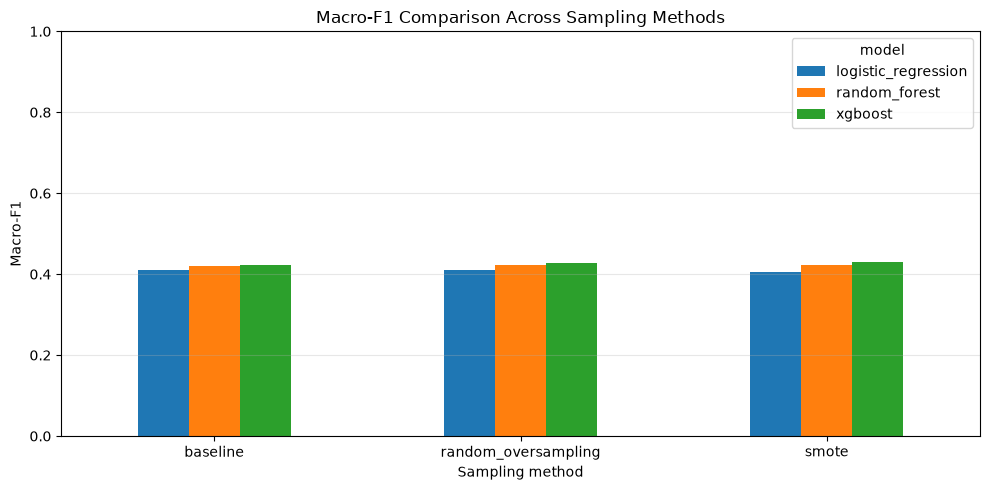

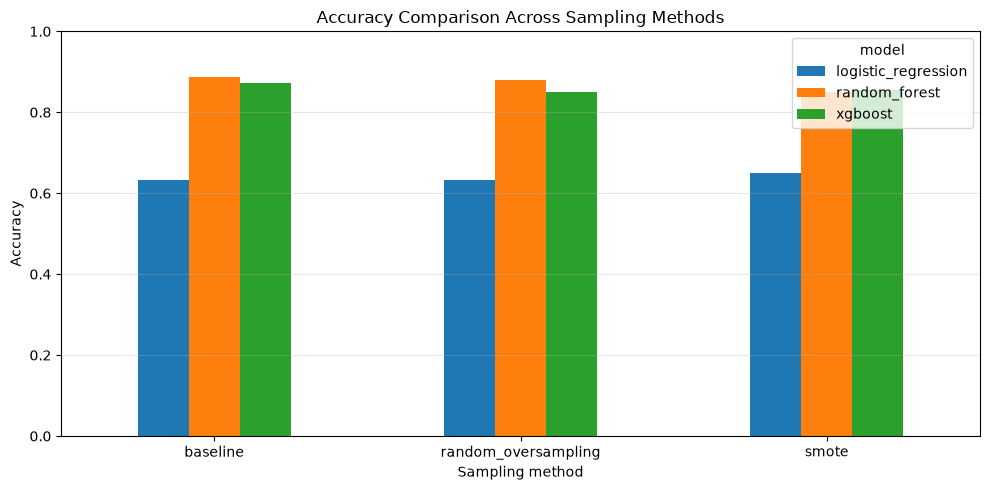

Saved comparison table and plots to: results\notebook_analysis


In [21]:
RESULTS_DIR = Path("results/resampling_experiment")
OUTPUT_DIR = Path("results/notebook_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rows = []

for experiment in ["baseline", "random_oversampling", "smote"]:
    for model in ["logistic_regression", "random_forest", "xgboost"]:
        report_path = RESULTS_DIR / experiment / model / f"{model}.json"

        if not report_path.exists():
            print(f"Missing report: {report_path}")
            continue

        with open(report_path, "r", encoding="utf-8") as f:
            report = json.load(f)

        rows.append({
            "experiment": experiment,
            "model": model,
            "accuracy": report.get("accuracy", 0),
            "macro_f1": report.get("macro_f1", 0),
            "test_balanced_accuracy": (
                report.get("test_balanced_accuracy", None)
            )
        })

comparison = pd.DataFrame(rows)

if comparison.empty:
    print("No reports loaded. Check the report paths.")
else:
    display(comparison.round(4))

    comparison.to_csv(
        OUTPUT_DIR / "experiment_level_comparison.csv",
        index=False
    )

    # Macro-F1 comparison
    pivot_f1 = comparison.pivot(
        index="experiment",
        columns="model",
        values="macro_f1"
    ).reindex(["baseline", "random_oversampling", "smote"])

    ax = pivot_f1.plot(kind="bar", figsize=(10, 5))
    ax.set_title("Macro-F1 Comparison Across Sampling Methods")
    ax.set_xlabel("Sampling method")
    ax.set_ylabel("Macro-F1")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "experiment_macro_f1_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    # Accuracy comparison
    pivot_accuracy = comparison.pivot(
        index="experiment",
        columns="model",
        values="accuracy"
    ).reindex(["baseline", "random_oversampling", "smote"])

    ax = pivot_accuracy.plot(kind="bar", figsize=(10, 5))
    ax.set_title("Accuracy Comparison Across Sampling Methods")
    ax.set_xlabel("Sampling method")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "experiment_accuracy_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print(f"Saved comparison table and plots to: {OUTPUT_DIR}")

In [22]:

balanced_accuracy = {
    ("baseline", "logistic_regression"): 0.427968,
    ("baseline", "random_forest"): 0.402207,
    ("baseline", "xgboost"): 0.412732,
    ("random_oversampling", "logistic_regression"): 0.426517,
    ("random_oversampling", "random_forest"): 0.406495,
    ("random_oversampling", "xgboost"): 0.430213,
    ("smote", "logistic_regression"): 0.412513,
    ("smote", "random_forest"): 0.453910,
    ("smote", "xgboost"): 0.438753,
}

comparison["test_balanced_accuracy"] = comparison.apply(
    lambda row: balanced_accuracy.get(
        (row["experiment"], row["model"])
    ),
    axis=1
)

display(comparison.round(4))

comparison.to_csv(
    OUTPUT_DIR / "experiment_level_comparison.csv",
    index=False
)

print("Updated comparison table saved.")


,experiment,model,accuracy,macro_f1,test_balanced_accuracy
0,baseline,logistic_regression,0.6332,0.4100,0.4280
1,baseline,random_forest,0.8880,0.4210,0.4022
2,baseline,xgboost,0.8720,0.4222,0.4127
3,random_oversampling,logistic_regression,0.6328,0.4093,0.4265
4,random_oversampling,random_forest,0.8786,0.4224,0.4065
5,random_oversampling,xgboost,0.8504,0.4277,0.4302
6,smote,logistic_regression,0.6489,0.4065,0.4125
7,smote,random_forest,0.8504,0.4235,0.4539
8,smote,xgboost,0.8551,0.4301,0.4388


Updated comparison table saved.


,experiment,model,class,recall,f1_score
3,baseline,logistic_regression,F,0.1364,0.0029
15,random_oversampling,logistic_regression,F,0.1364,0.0029
27,smote,logistic_regression,F,0.0909,0.0021
7,baseline,random_forest,F,0.0000,0.0000
19,random_oversampling,random_forest,F,0.0000,0.0000
31,smote,random_forest,F,0.1818,0.0082
11,baseline,xgboost,F,0.0455,0.0029
23,random_oversampling,xgboost,F,0.0909,0.0040
35,smote,xgboost,F,0.1364,0.0057
1,baseline,logistic_regression,S,0.2220,0.0756


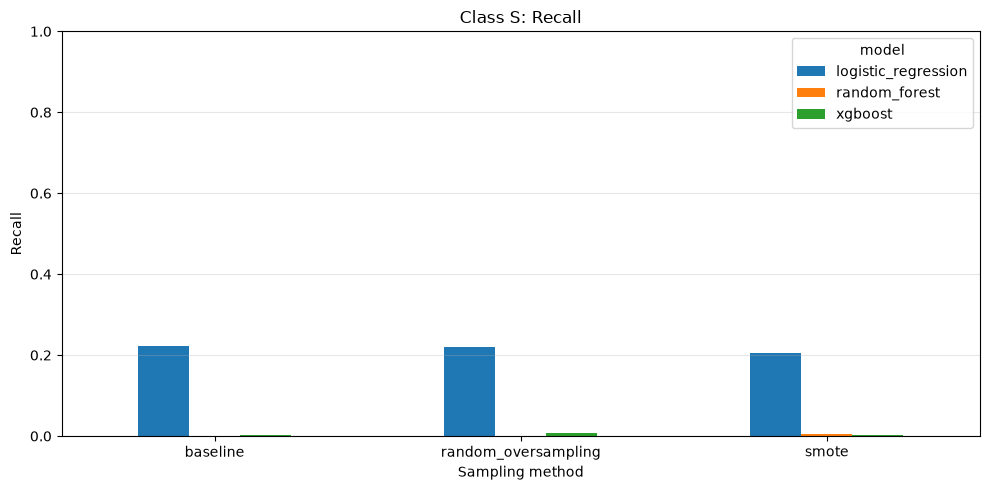

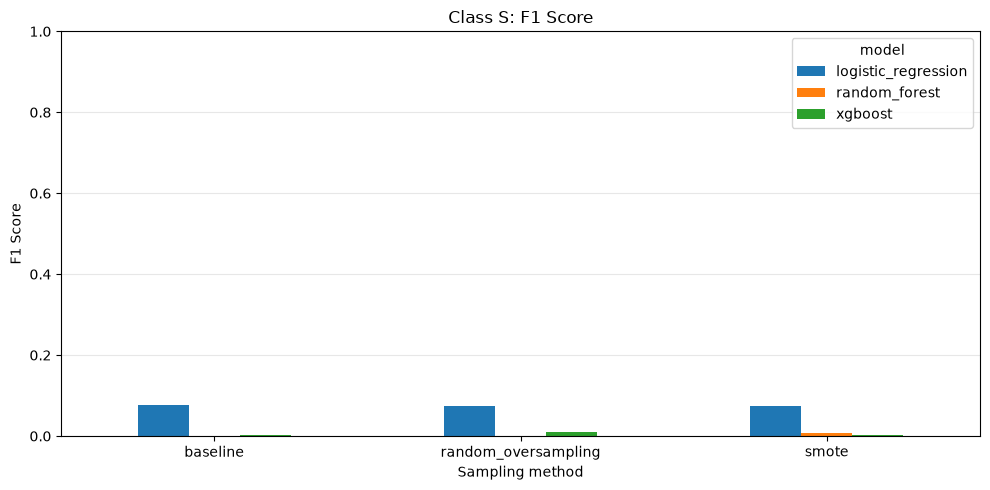

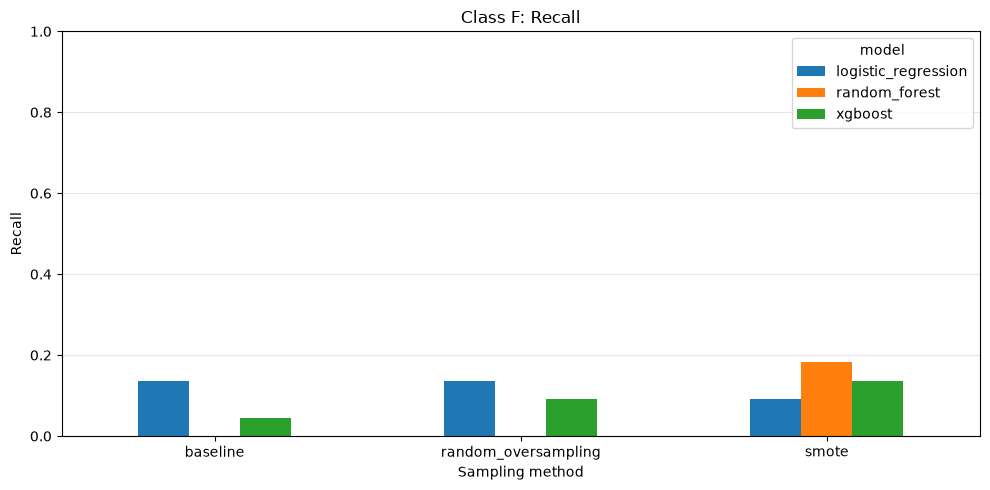

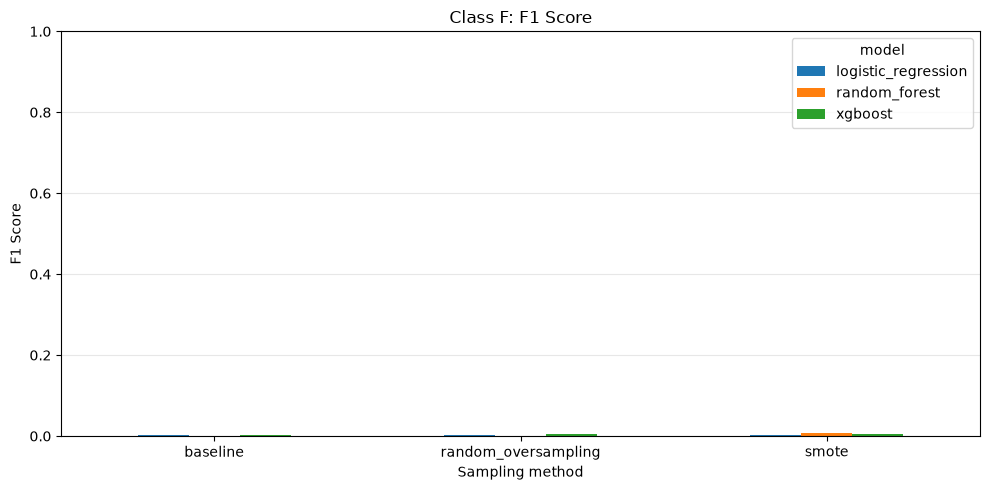

Saved minority-class analysis to: results\notebook_analysis


In [23]:

# Compare per-class recall and F1 across sampling experiments
RESULTS_DIR = Path("results/resampling_experiment")
OUTPUT_DIR = Path("results/notebook_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rows = []

for experiment in ["baseline", "random_oversampling", "smote"]:
    for model in ["logistic_regression", "random_forest", "xgboost"]:
        path = RESULTS_DIR / experiment / model / f"{model}.json"

        with open(path, "r", encoding="utf-8") as f:
            report = json.load(f)

        for cls in ["N", "S", "V", "F"]:
            metrics = report["classification_report"][cls]
            rows.append({
                "experiment": experiment,
                "model": model,
                "class": cls,
                "recall": metrics["recall"],
                "f1_score": metrics["f1-score"]
            })

per_class = pd.DataFrame(rows)

display(
    per_class[per_class["class"].isin(["S", "F"])]
    .sort_values(["class", "model", "experiment"])
    .round(4)
)

per_class.to_csv(
    OUTPUT_DIR / "per_class_sampling_metrics.csv",
    index=False
)

for cls in ["S", "F"]:
    subset = per_class[per_class["class"] == cls]

    for metric in ["recall", "f1_score"]:
        pivot = subset.pivot(
            index="experiment",
            columns="model",
            values=metric
        ).reindex(["baseline", "random_oversampling", "smote"])

        ax = pivot.plot(kind="bar", figsize=(10, 5))
        ax.set_title(f"Class {cls}: {metric.replace('_', ' ').title()}")
        ax.set_xlabel("Sampling method")
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.set_ylim(0, 1)
        ax.grid(axis="y", alpha=0.3)
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"class_{cls}_{metric}_comparison.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

print("Saved minority-class analysis to:", OUTPUT_DIR)


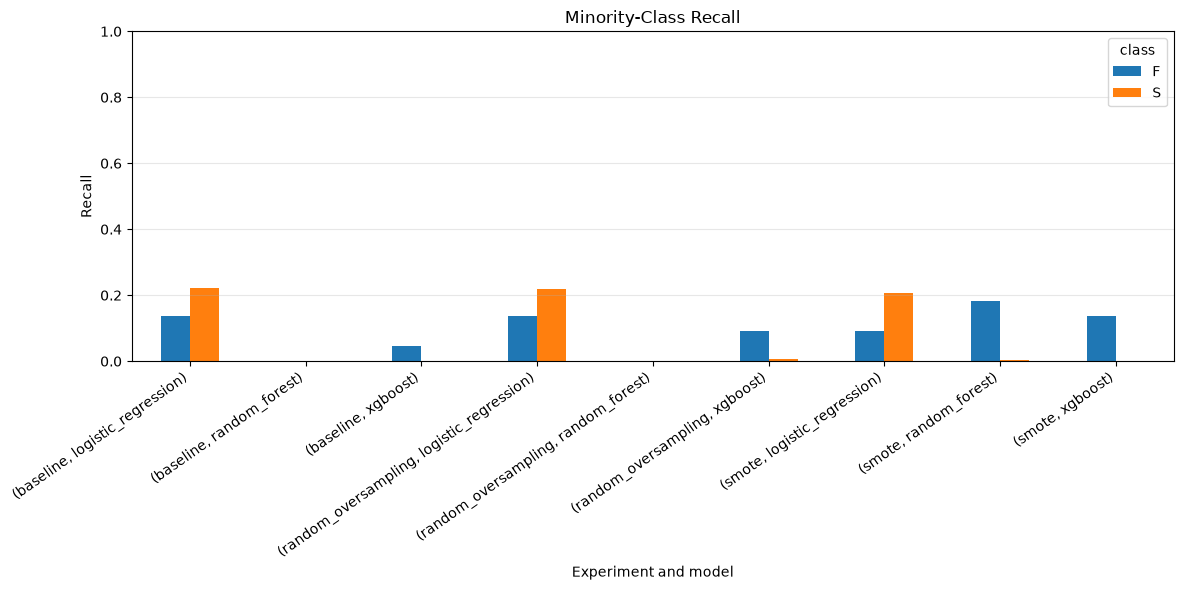

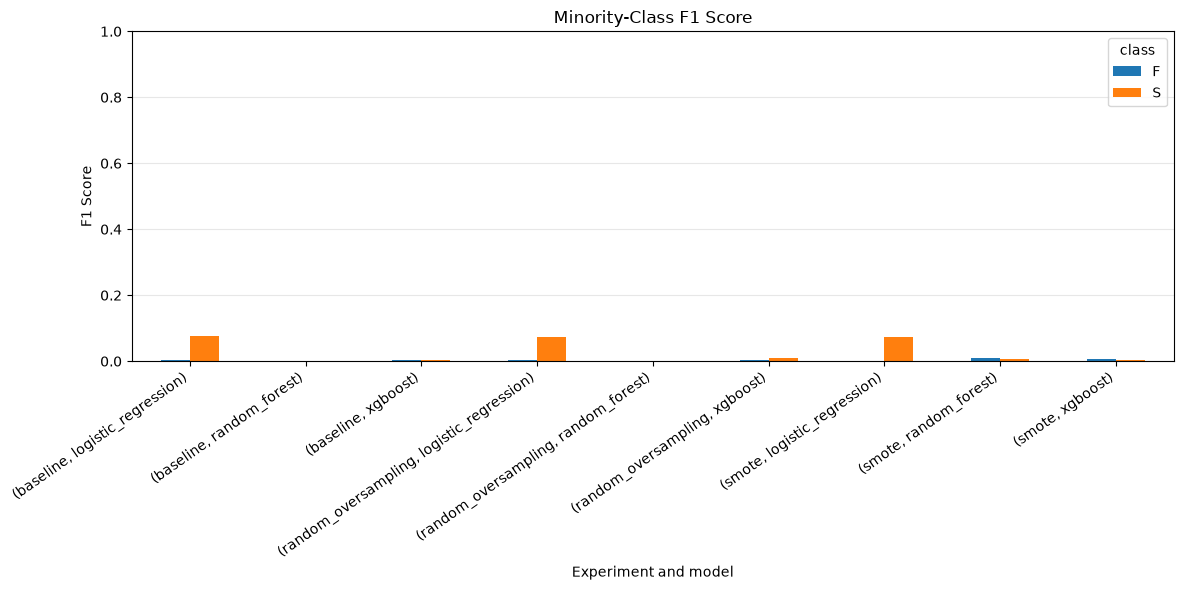

Minority-class charts saved to: E:\minor\NEUROCARDIO_AI\backend\models\ecg_paper_reproduction\results\notebook_analysis


In [24]:
OUTPUT_DIR = Path("results/notebook_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

minority = df[df["class"].isin(["S", "F"])].copy()

for metric in ["recall", "f1_score"]:
    pivot = minority.pivot_table(
        index=["experiment", "model"],
        columns="class",
        values=metric,
        aggfunc="mean"
    )

    ax = pivot.plot(kind="bar", figsize=(12, 6))
    ax.set_title(f"Minority-Class {metric.replace('_', ' ').title()}")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.set_xlabel("Experiment and model")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"minority_class_{metric}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("Minority-class charts saved to:", OUTPUT_DIR.resolve())

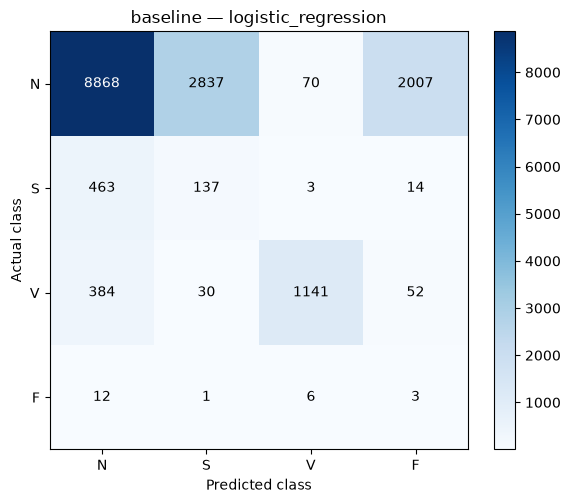

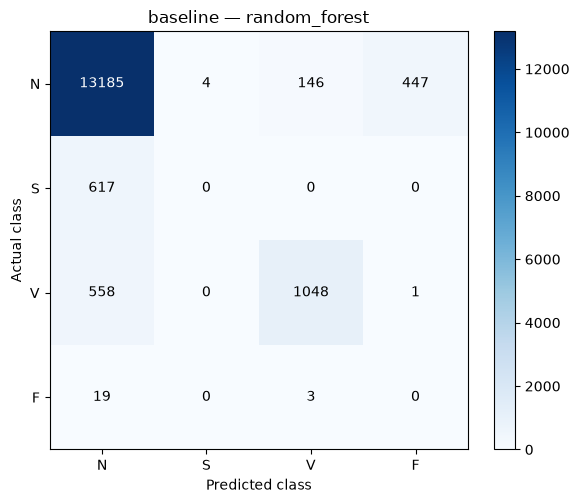

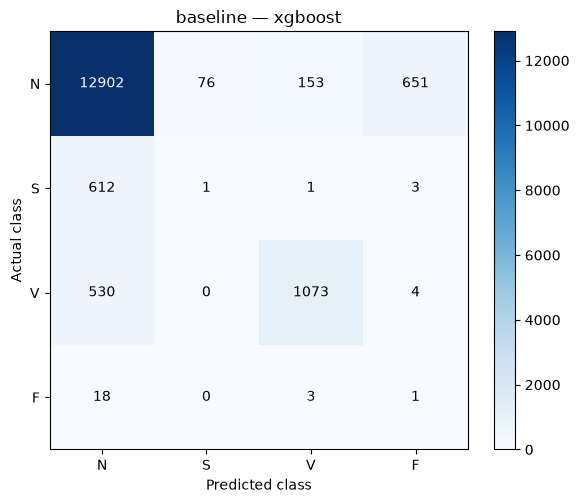

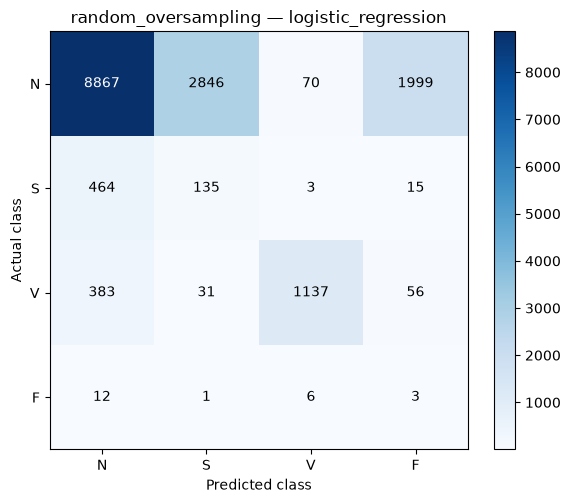

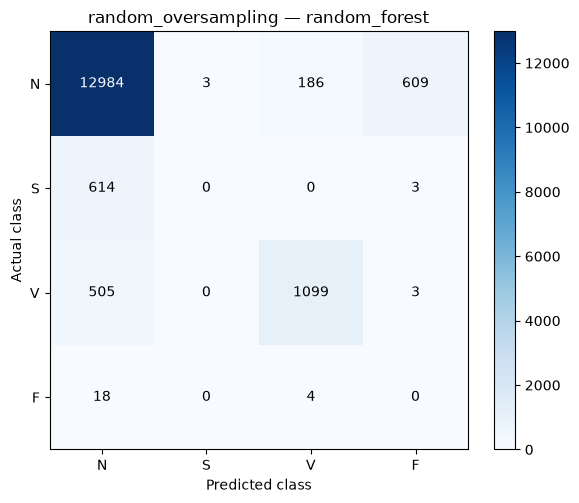

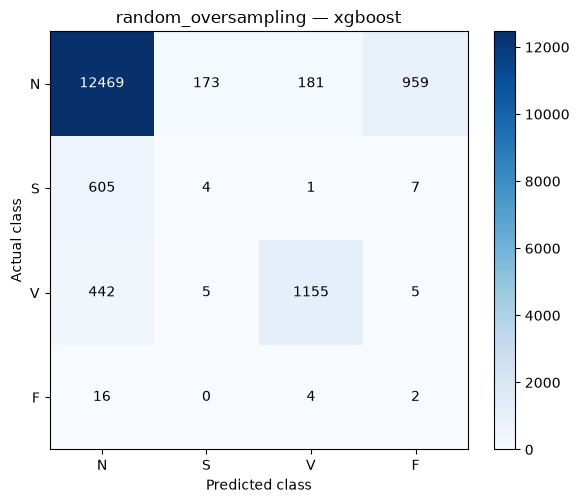

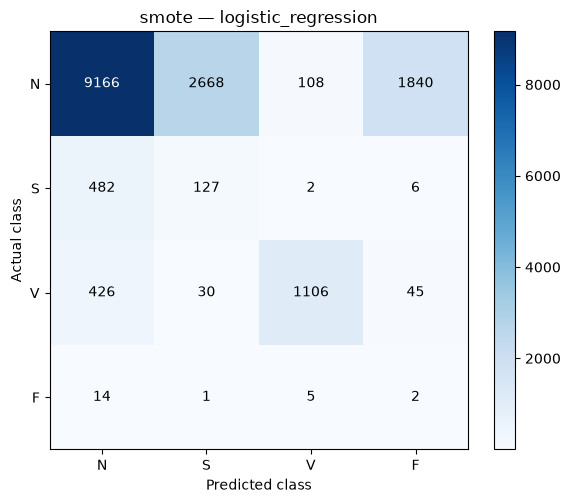

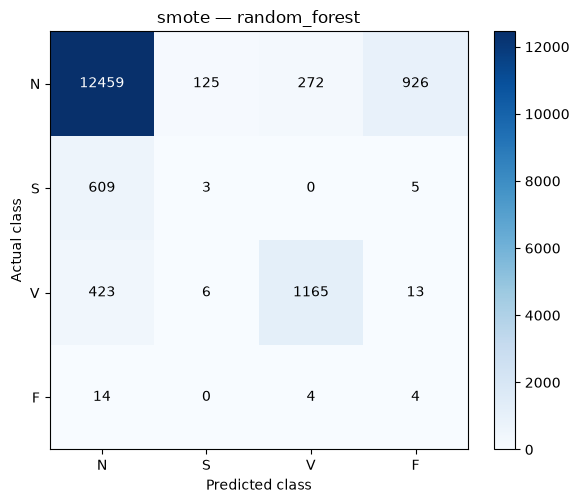

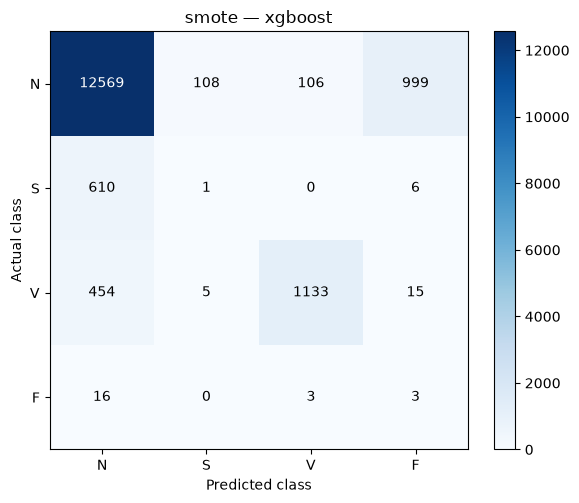

Finished checking confusion matrices.


In [26]:
RESULTS_DIR = Path("results/resampling_experiment")
OUTPUT_DIR = Path("results/notebook_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for experiment in ["baseline", "random_oversampling", "smote"]:
    for model in ["logistic_regression", "random_forest", "xgboost"]:

        report_path = (
            RESULTS_DIR / experiment / model / f"{model}.json"
        )

        if not report_path.exists():
            print("Missing:", report_path)
            continue

        with open(report_path, "r", encoding="utf-8") as f:
            report = json.load(f)

        if "confusion_matrix" not in report:
            print(f"No confusion matrix stored in {report_path}")
            continue

        cm = np.array(report["confusion_matrix"])

        fig, ax = plt.subplots(figsize=(6, 5))
        image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
        fig.colorbar(image, ax=ax)

        classes = ["N", "S", "V", "F"]
        ax.set(
            xticks=np.arange(4),
            yticks=np.arange(4),
            xticklabels=classes,
            yticklabels=classes,
            xlabel="Predicted class",
            ylabel="Actual class",
            title=f"{experiment} — {model}"
        )

        threshold = cm.max() / 2 if cm.size else 0
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(
                    j, i, str(cm[i, j]),
                    ha="center",
                    va="center",
                    color="white" if cm[i, j] > threshold else "black"
                )

        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR / f"{experiment}_{model}_confusion_matrix.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

print("Finished checking confusion matrices.")

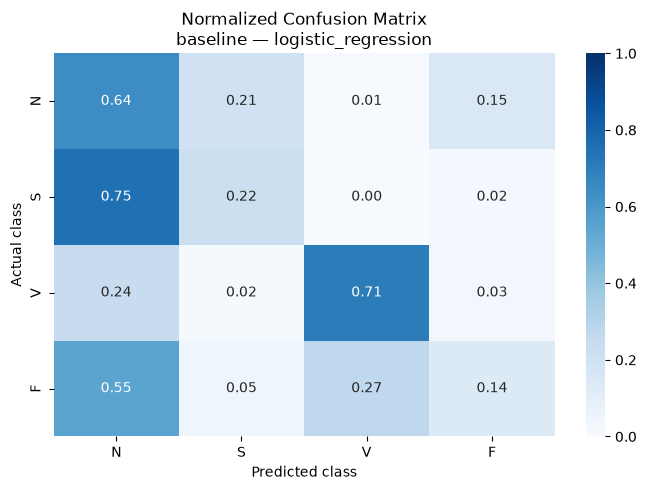

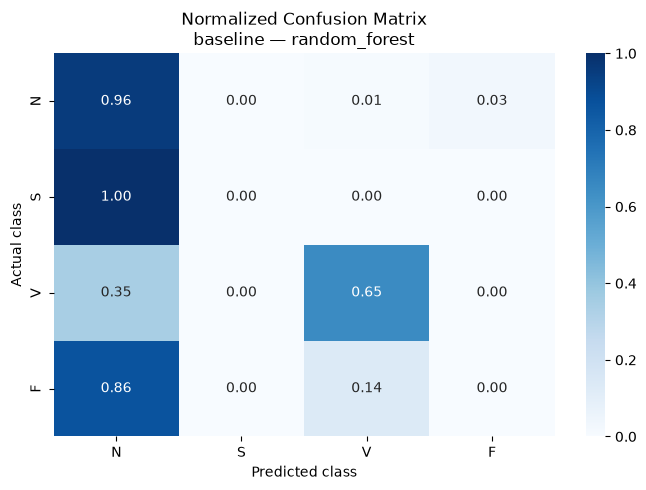

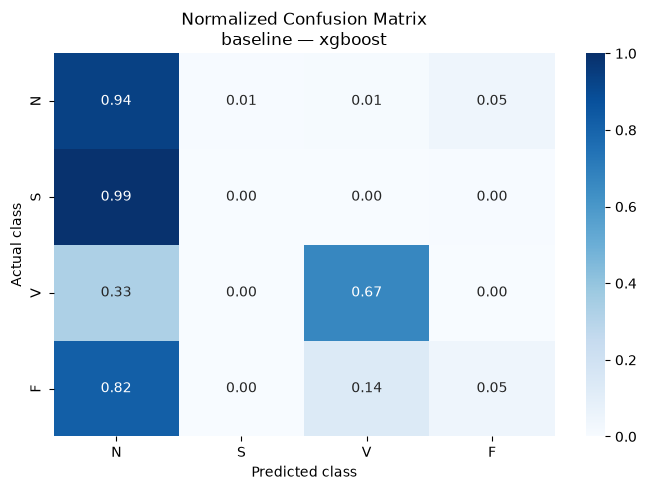

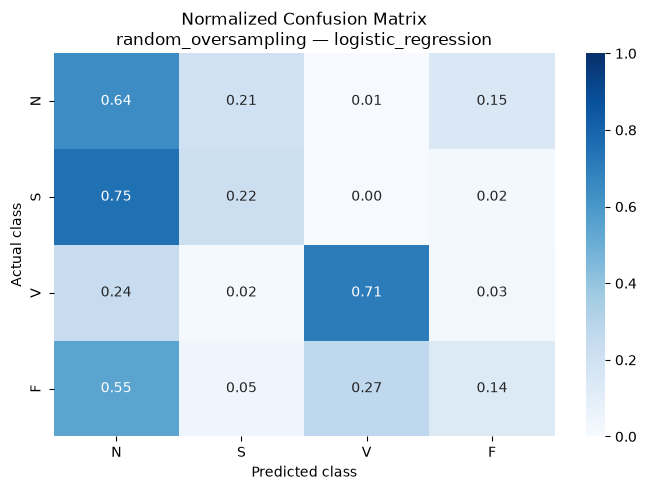

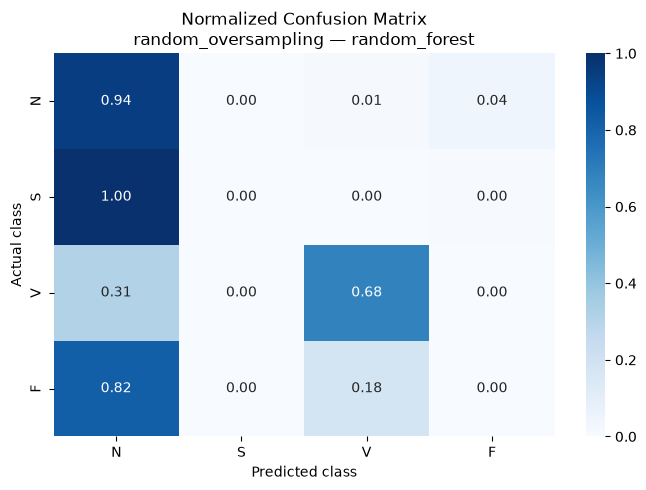

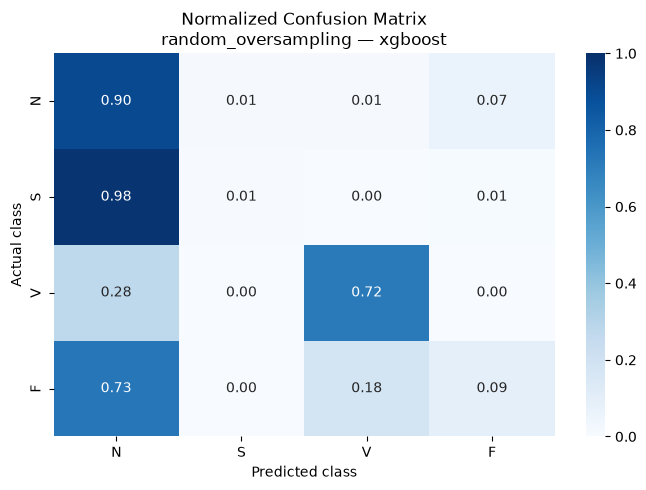

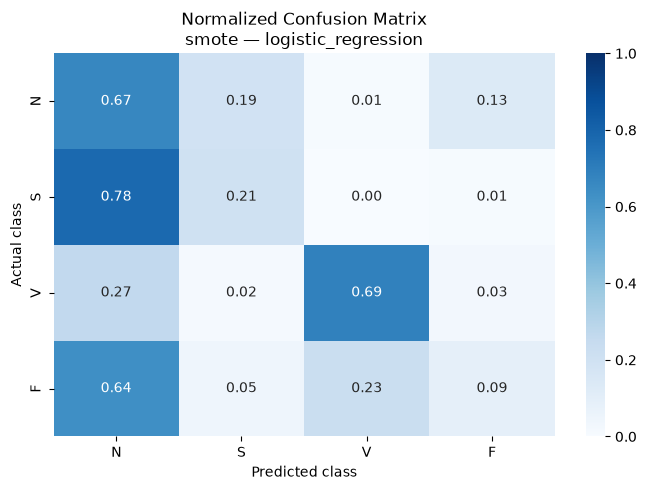

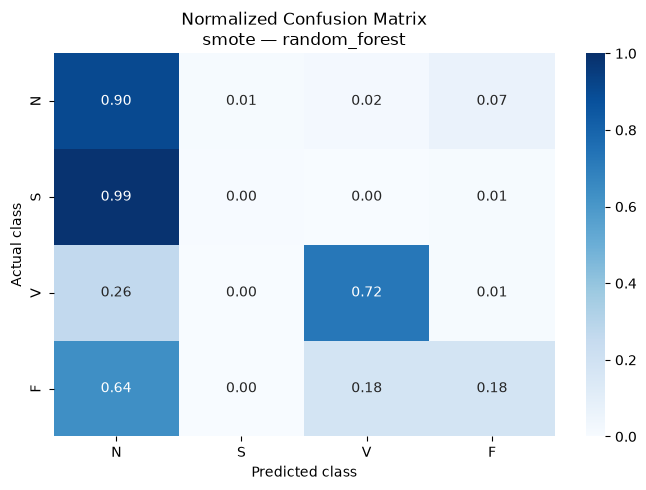

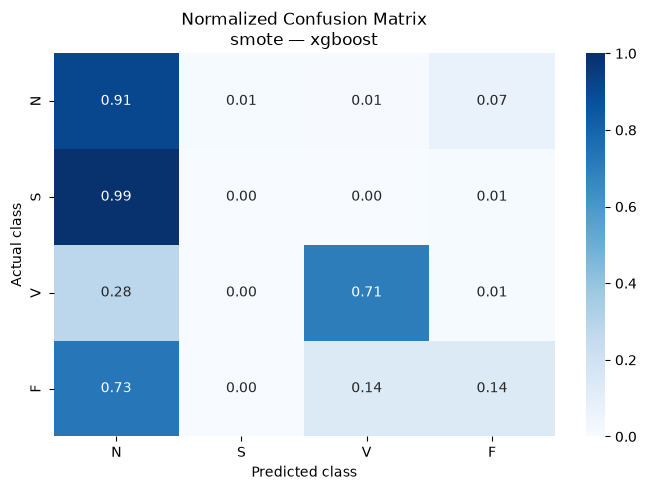

Finished. Check: E:\minor\NEUROCARDIO_AI\backend\models\ecg_paper_reproduction\results\notebook_analysis


In [27]:

import seaborn as sns
from sklearn.metrics import confusion_matrix

RESULTS_DIR = Path("results/resampling_experiment")
OUTPUT_DIR = Path("results/notebook_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["N", "S", "V", "F"]

for experiment in ["baseline", "random_oversampling", "smote"]:
    for model in ["logistic_regression", "random_forest", "xgboost"]:

        report_path = RESULTS_DIR / experiment / model / f"{model}.json"

        if not report_path.exists():
            print(f"Skipping missing file: {report_path}")
            continue

        with open(report_path, "r", encoding="utf-8") as f:
            report = json.load(f)

        # A saved classification report does not contain the
        # individual predictions needed to reconstruct a confusion matrix.
        # Use the confusion matrix section only if your JSON stores it.
        cm = report.get("confusion_matrix")

        if cm is None:
            print(f"No saved confusion matrix in {report_path}")
            continue

        cm = np.asarray(cm)
        row_sums = cm.sum(axis=1, keepdims=True)
        normalized_cm = np.divide(
            cm,
            row_sums,
            out=np.zeros_like(cm, dtype=float),
            where=row_sums != 0
        )

        plt.figure(figsize=(7, 5))
        sns.heatmap(
            normalized_cm,
            annot=True,
            fmt=".2f",
            cmap="Blues",
            xticklabels=CLASSES,
            yticklabels=CLASSES,
            vmin=0,
            vmax=1
        )
        plt.title(f"Normalized Confusion Matrix\n{experiment} — {model}")
        plt.xlabel("Predicted class")
        plt.ylabel("Actual class")
        plt.tight_layout()

        filename = f"{experiment}_{model}_normalized_cm.png"
        plt.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()

print(f"Finished. Check: {OUTPUT_DIR.resolve()}")


,experiment,model,accuracy,macro_f1,test_balanced_accuracy
0,smote,xgboost,0.8551,0.4301,0.4388
1,random_oversampling,xgboost,0.8504,0.4277,0.4302
2,smote,random_forest,0.8504,0.4235,0.4539
3,random_oversampling,random_forest,0.8786,0.4224,0.4065
4,baseline,xgboost,0.8720,0.4222,0.4127
5,baseline,random_forest,0.8880,0.4210,0.4022
6,baseline,logistic_regression,0.6332,0.4100,0.4280
7,random_oversampling,logistic_regression,0.6328,0.4093,0.4265
8,smote,logistic_regression,0.6489,0.4065,0.4125


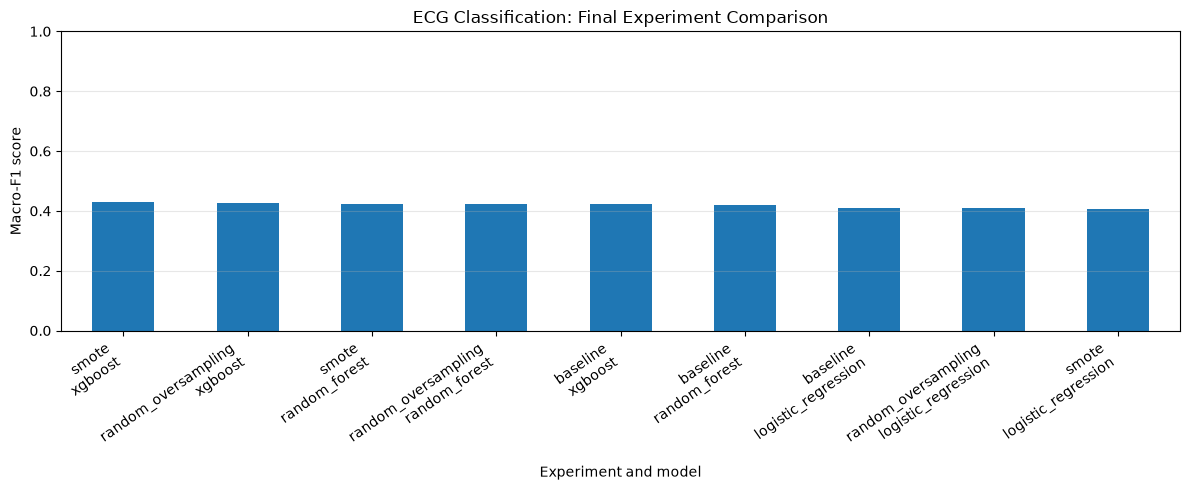

Final summary and plot saved in: E:\minor\NEUROCARDIO_AI\backend\models\ecg_paper_reproduction\results\notebook_analysis


In [28]:
OUTPUT_DIR = Path("results/notebook_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Summarise the baseline, random oversampling, and SMOTE experiments
summary = comparison.copy()

summary = summary.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)

display(summary.round(4))

summary.to_csv(
    OUTPUT_DIR / "final_experiment_summary.csv",
    index=False
)

# Plot macro-F1 for all model and sampling combinations
plot_data = summary.copy()
plot_data["experiment_model"] = (
    plot_data["experiment"] + "\n" + plot_data["model"]
)

ax = plot_data.plot(
    x="experiment_model",
    y="macro_f1",
    kind="bar",
    figsize=(12, 5),
    legend=False,
    ylim=(0, 1)
)

ax.set_title("ECG Classification: Final Experiment Comparison")
ax.set_xlabel("Experiment and model")
ax.set_ylabel("Macro-F1 score")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_macro_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Final summary and plot saved in:", OUTPUT_DIR.resolve())